{'python': '3.13.16', 'tensorflow': '2.21.0', 'keras': '3.13.2'} GPU


README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

['angular_leaf_spot', 'bean_rust', 'healthy'] {'train': [345, 348, 341], 'val': [44, 45, 44], 'test': [43, 43, 42]} imbalance 1.02 dups {'train_val': 0, 'train_test': 0, 'val_test': 0, 'within_train': 0}


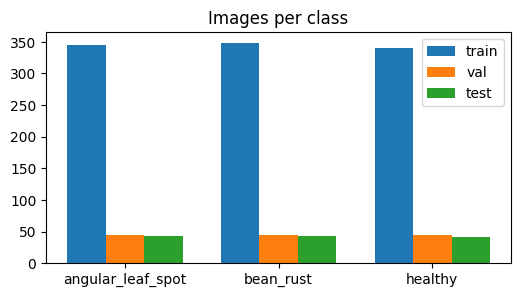

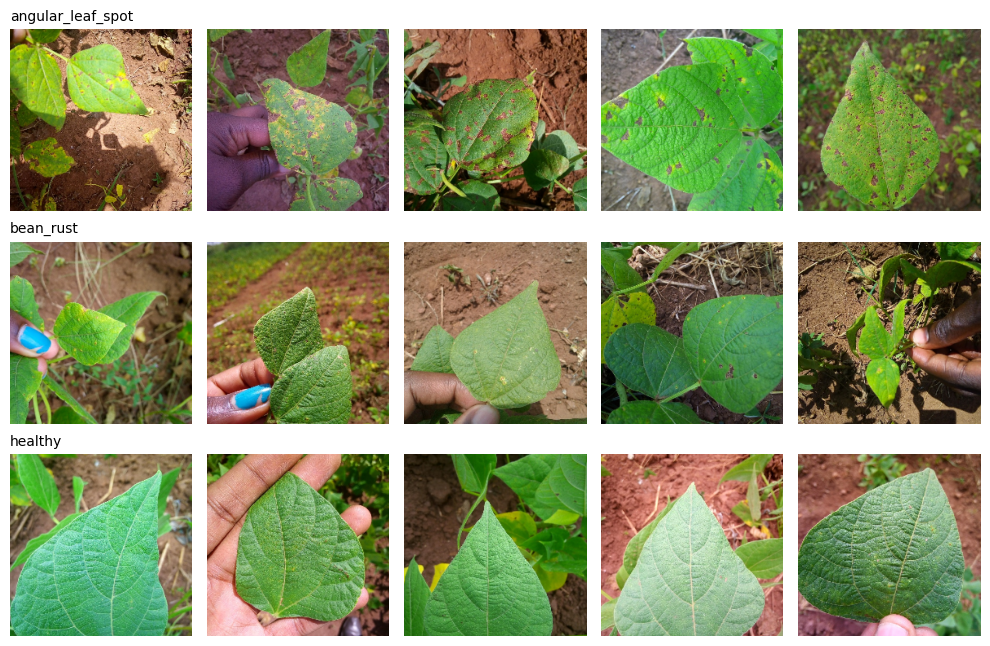

In [ ]:
!pip -q install datasets
import os, json, time, random, hashlib, platform
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf, keras
from keras import layers
from datasets import load_dataset
from sklearn.metrics import classification_report, confusion_matrix, f1_score

SEED, IMG, BATCH = 42, 224, 32
OUT = "outputs"; os.makedirs(OUT, exist_ok=True)
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
GPUS = tf.config.list_physical_devices("GPU")
DEVICE = "GPU" if GPUS else "CPU"
VERSIONS = dict(python=platform.python_version(), tensorflow=tf.__version__, keras=keras.__version__)
print(VERSIONS, DEVICE)

raw = load_dataset("AI-Lab-Makerere/beans")          # official splits: train / validation / test
CLASS_NAMES = raw["train"].features["labels"].names; NC = len(CLASS_NAMES)

def to_numpy(split):
    X, y, H = [], [], []
    for ex in raw[split]:
        arr = np.array(ex["image"].convert("RGB"))
        H.append(hashlib.md5(arr.tobytes()).hexdigest())
        X.append(tf.image.resize(arr, (IMG, IMG)).numpy().round().astype("uint8")); y.append(int(ex["labels"]))
    return np.stack(X), np.array(y), H
X_tr, y_tr, H_tr = to_numpy("train"); X_va, y_va, H_va = to_numpy("validation"); X_te, y_te, H_te = to_numpy("test")

counts = {k: np.bincount(v, minlength=NC).tolist() for k, v in dict(train=y_tr, val=y_va, test=y_te).items()}
imb_ratio = max(counts["train"]) / min(counts["train"])
dup = dict(train_val=len(set(H_tr)&set(H_va)), train_test=len(set(H_tr)&set(H_te)),
           val_test=len(set(H_va)&set(H_te)), within_train=len(H_tr)-len(set(H_tr)))
print(CLASS_NAMES, counts, "imbalance", round(imb_ratio, 2), "dups", dup)

fig, ax = plt.subplots(figsize=(6,3)); w = 0.25
for i,(k,v) in enumerate(counts.items()): ax.bar(np.arange(NC)+i*w, v, w, label=k)
ax.set_xticks(np.arange(NC)+w); ax.set_xticklabels(CLASS_NAMES); ax.legend(); ax.set_title("Images per class")
plt.savefig(f"{OUT}/class_balance.png", dpi=150); plt.show()
fig, axes = plt.subplots(NC, 5, figsize=(10, 2.2*NC))
for c in range(NC):
    for j, i in enumerate(np.where(y_tr==c)[0][:5]):
        axes[c,j].imshow(X_tr[i]); axes[c,j].axis("off")
        if j==0: axes[c,j].set_title(CLASS_NAMES[c], loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(f"{OUT}/samples.png", dpi=120); plt.show()

In [ ]:
def make_ds(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y)).map(lambda a, b: (tf.cast(a, tf.float32), b))
    if training: ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)
ds_tr, ds_va, ds_te = make_ds(X_tr,y_tr,True), make_ds(X_va,y_va,False), make_ds(X_te,y_te,False)
CW = {c: len(y_tr)/(NC*n) for c, n in enumerate(np.bincount(y_tr, minlength=NC))}

def augmenter():
    return keras.Sequential([layers.RandomFlip("horizontal_and_vertical"), layers.RandomRotation(0.08),
                             layers.RandomZoom(0.15), layers.RandomContrast(0.15)], name="augment")

def build_scratch(augment=True):
    inp = keras.Input((IMG,IMG,3)); x = inp
    if augment: x = augmenter()(x)
    x = layers.Rescaling(1/255.)(x)
    for f in (32,64,128):
        x = layers.Conv2D(f,3,padding="same",use_bias=False)(x)
        x = layers.BatchNormalization()(x); x = layers.ReLU()(x); x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D(name="gap")(x); x = layers.Dropout(0.4, name="drop")(x)
    return keras.Model(inp, layers.Dense(NC, activation="softmax", name="pred")(x), name="scratch_cnn"), None

def build_mobilenet(augment=True):
    base = keras.applications.MobileNetV2(input_shape=(IMG,IMG,3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = keras.Input((IMG,IMG,3)); x = inp
    if augment: x = augmenter()(x)
    x = layers.Rescaling(1/127.5, offset=-1)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x); x = layers.Dropout(0.3, name="drop")(x)
    return keras.Model(inp, layers.Dense(NC, activation="softmax", name="pred")(x), name="mobilenetv2_beans"), base

def fit_phases(model, base, phases):
    hist = {k: [] for k in ("accuracy","val_accuracy","loss","val_loss")}; t0, boundary = time.time(), None
    for epochs, lr, unfreeze in phases:
        if unfreeze and base is not None:
            base.trainable = True
            for l in base.layers[:-unfreeze]: l.trainable = False
            for l in base.layers:
                if isinstance(l, layers.BatchNormalization): l.trainable = False
            boundary = len(hist["loss"])
        model.compile(keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        cb = [keras.callbacks.EarlyStopping("val_loss", patience=6, restore_best_weights=True),
              keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.5, patience=3, min_lr=1e-7)]
        h = model.fit(ds_tr, validation_data=ds_va, epochs=epochs, class_weight=CW, callbacks=cb, verbose=2)
        for k in hist: hist[k] += [float(v) for v in h.history[k]]
    return hist, time.time()-t0, boundary

EXPS = {}
def run(name, build_fn, phases):
    print(f"\n===== {name} =====")
    tf.keras.utils.set_random_seed(SEED)
    model, base = build_fn()
    hist, secs, boundary = fit_phases(model, base, phases)
    p = model.predict(ds_va, verbose=0).argmax(1)
    EXPS[name] = dict(model=model, base=base, hist=hist, time=secs, boundary=boundary,
        val_acc=float((p==y_va).mean()*100), val_f1=float(f1_score(y_va,p,average="macro")*100),
        params=int(model.count_params()))
    print(f"-> val acc {EXPS[name]['val_acc']:.2f} | val F1 {EXPS[name]['val_f1']:.2f} | {secs:.0f}s")

TL = [(20,1e-3,0),(15,1e-5,40)]
run("Scratch CNN (aug)",    lambda: build_scratch(True),    [(40,1e-3,0)])
run("MobileNetV2 (no aug)", lambda: build_mobilenet(False), TL)
run("MobileNetV2 (aug)",    lambda: build_mobilenet(True),  TL)
BEST = max(EXPS, key=lambda k: (EXPS[k]["val_f1"], EXPS[k]["val_acc"]))
print("\nSelected on validation:", BEST)


===== Scratch CNN (aug) =====
Epoch 1/40
33/33 - 19s - 566ms/step - accuracy: 0.6044 - loss: 0.9482 - val_accuracy: 0.3308 - val_loss: 1.1559 - learning_rate: 0.0010
Epoch 2/40
33/33 - 4s - 121ms/step - accuracy: 0.6538 - loss: 0.7679 - val_accuracy: 0.3910 - val_loss: 1.3135 - learning_rate: 0.0010
Epoch 3/40
33/33 - 4s - 124ms/step - accuracy: 0.6818 - loss: 0.7382 - val_accuracy: 0.4135 - val_loss: 1.1243 - learning_rate: 0.0010
Epoch 4/40
33/33 - 4s - 125ms/step - accuracy: 0.6828 - loss: 0.6988 - val_accuracy: 0.4060 - val_loss: 1.5248 - learning_rate: 0.0010
Epoch 5/40
33/33 - 4s - 123ms/step - accuracy: 0.6828 - loss: 0.7008 - val_accuracy: 0.4511 - val_loss: 1.9886 - learning_rate: 0.0010
Epoch 6/40
33/33 - 4s - 125ms/step - accuracy: 0.7176 - loss: 0.6737 - val_accuracy: 0.3609 - val_loss: 1.9969 - learning_rate: 0.0010
Epoch 7/40
33/33 - 4s - 132ms/step - accuracy: 0.7311 - loss: 0.6498 - val_accuracy: 0.3684 - val_loss: 1.9328 - learning_rate: 5.0000e-04
Epoch 8/40
33/33 - 

-> val acc 93.98 | val F1 93.92 | 120s

Selected on validation: MobileNetV2 (no aug)


                   precision    recall  f1-score   support

angular_leaf_spot     0.8269    1.0000    0.9053        43
        bean_rust     0.9706    0.7674    0.8571        43
          healthy     0.9762    0.9762    0.9762        42

         accuracy                         0.9141       128
        macro avg     0.9246    0.9145    0.9129       128
     weighted avg     0.9242    0.9141    0.9124       128

[[43  0  0]
 [ 9 33  1]
 [ 0  1 41]]


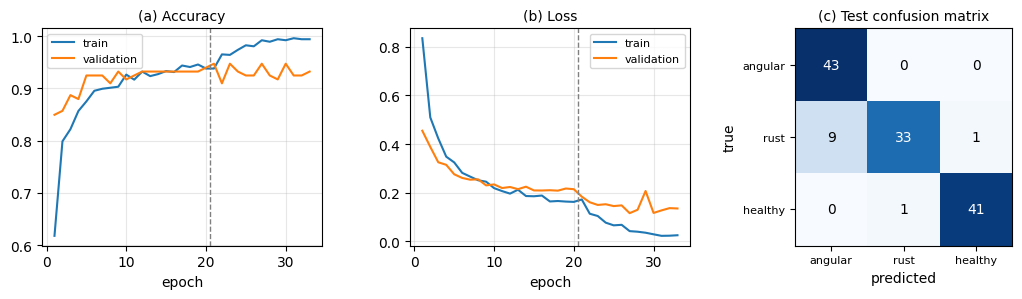

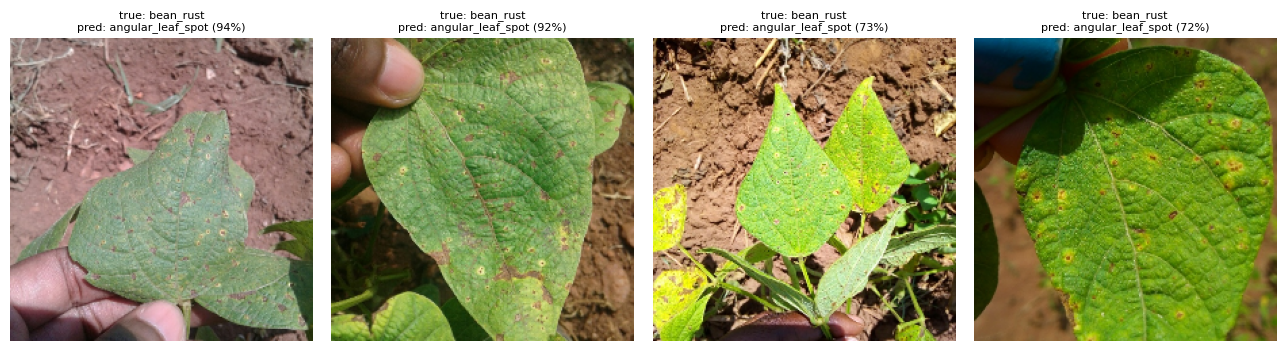

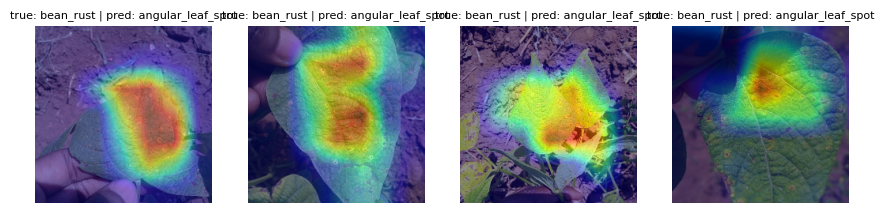

In [ ]:
E = EXPS[BEST]; model, base = E["model"], E["base"]
probs = model.predict(ds_te, verbose=0); y_pred = probs.argmax(1)
test_acc = float((y_pred==y_te).mean()*100); test_f1 = float(f1_score(y_te,y_pred,average="macro")*100)
rep = classification_report(y_te, y_pred, target_names=CLASS_NAMES, output_dict=True)
cm = confusion_matrix(y_te, y_pred, labels=range(NC))
print(classification_report(y_te, y_pred, target_names=CLASS_NAMES, digits=4)); print(cm)

h = E["hist"]; be = int(np.argmin(h["val_loss"]))
train_acc_be, val_acc_be = h["accuracy"][be]*100, h["val_accuracy"][be]*100
model.save(f"{OUT}/best_model.keras"); size_mb = os.path.getsize(f"{OUT}/best_model.keras")/1e6
x1 = tf.cast(X_te[:1], tf.float32); model(x1, training=False)
t0 = time.time(); [model(x1, training=False) for _ in range(30)]; latency_ms = (time.time()-t0)/30*1000

# Fig 1: curves + confusion matrix
ep = np.arange(1, len(h["loss"])+1)
fig, ax = plt.subplots(1,3, figsize=(10.5,3.1), gridspec_kw=dict(width_ratios=[1,1,0.9]))
for a,key,ttl in ((ax[0],"accuracy","(a) Accuracy"),(ax[1],"loss","(b) Loss")):
    a.plot(ep,h[key],label="train"); a.plot(ep,h["val_"+key],label="validation")
    if E["boundary"]: a.axvline(E["boundary"]+0.5, ls="--", c="gray", lw=1)
    a.set_title(ttl, fontsize=10); a.set_xlabel("epoch"); a.legend(fontsize=8); a.grid(alpha=.3)
ax[2].imshow(cm, cmap="Blues"); ax[2].set_title("(c) Test confusion matrix", fontsize=10)
short = ["angular","rust","healthy"]
ax[2].set_xticks(range(NC)); ax[2].set_yticks(range(NC)); ax[2].set_xticklabels(short, fontsize=8); ax[2].set_yticklabels(short, fontsize=8)
ax[2].set_xlabel("predicted"); ax[2].set_ylabel("true")
for i in range(NC):
    for j in range(NC): ax[2].text(j,i,cm[i,j],ha="center",va="center",color="white" if cm[i,j]>cm.max()/2 else "black")
plt.tight_layout(); plt.savefig(f"{OUT}/fig1_curves_cm.png", dpi=200); plt.show()

# Misclassified images (write your own one-line reason for each for the viva)
conf = probs.max(1); wrong = np.where(y_pred!=y_te)[0]; wrong = wrong[np.argsort(-conf[wrong])]
show = list(wrong[:8])
if len(show) < 4:
    right = np.where(y_pred==y_te)[0]; show += list(right[np.argsort(conf[right])][:4-len(show)])
fig, axes = plt.subplots(1, 4, figsize=(13,3.4))
for a,i in zip(axes, show[:4]):
    a.imshow(X_te[i]); a.axis("off")
    a.set_title(f"true: {CLASS_NAMES[y_te[i]]}\npred: {CLASS_NAMES[y_pred[i]]} ({conf[i]*100:.0f}%)", fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/misclassified.png", dpi=150); plt.show()

# Grad-CAM (MobileNetV2 only)
if base is not None:
    cam_model = keras.Model(base.input, base.get_layer("out_relu").output)
    def gradcam(img):
        x = tf.convert_to_tensor(img[None], tf.float32)/127.5 - 1.0
        with tf.GradientTape() as tape:
            fmap = cam_model(x, training=False)
            p = model.get_layer("pred")(model.get_layer("drop")(model.get_layer("gap")(fmap), training=False))
            score = p[:, int(tf.argmax(p[0]))]
        g = tape.gradient(score, fmap); w = tf.reduce_mean(g, axis=(1,2))
        cam = tf.nn.relu(tf.reduce_sum(fmap*w[:,None,None,:], axis=-1))[0]
        cam = (cam/(tf.reduce_max(cam)+1e-8)).numpy()
        return tf.image.resize(cam[...,None], (IMG,IMG)).numpy()[...,0]
    fig, axes = plt.subplots(1,4, figsize=(10.5,2.9))
    for k,i in enumerate(show[:4]):
        axes[k].imshow(X_te[i]); axes[k].imshow(gradcam(X_te[i].astype("float32")), cmap="jet", alpha=0.45); axes[k].axis("off")
        axes[k].set_title(f"true: {CLASS_NAMES[y_te[i]]} | pred: {CLASS_NAMES[y_pred[i]]}", fontsize=8)
    plt.savefig(f"{OUT}/fig2_gradcam.png", dpi=200); plt.show()

In [ ]:
S = dict(versions=VERSIONS, device=DEVICE, counts=counts, imbalance=round(imb_ratio,2), duplicates=dup,
  models={k: dict(val_acc=round(v["val_acc"],2), val_f1=round(v["val_f1"],2), time_s=round(v["time"]), params=v["params"]) for k,v in EXPS.items()},
  best=BEST, test_acc=round(test_acc,2), test_macro_f1=round(test_f1,2),
  per_class={c: [round(rep[c][m]*100,2) for m in ("precision","recall","f1-score")]+[int(rep[c]["support"])] for c in CLASS_NAMES},
  confusion_matrix=cm.tolist(), n_wrong=int(len(wrong)), train_acc_best_epoch=round(train_acc_be,2),
  val_acc_best_epoch=round(val_acc_be,2), size_mb=round(size_mb,1), latency_ms=round(latency_ms,1))
print(json.dumps(S))

{"versions": {"python": "3.13.16", "tensorflow": "2.21.0", "keras": "3.13.2"}, "device": "GPU", "counts": {"train": [345, 348, 341], "val": [44, 45, 44], "test": [43, 43, 42]}, "imbalance": 1.02, "duplicates": {"train_val": 0, "train_test": 0, "val_test": 0, "within_train": 0}, "models": {"Scratch CNN (aug)": {"val_acc": 41.35, "val_f1": 33.36, "time_s": 54, "params": 94307}, "MobileNetV2 (no aug)": {"val_acc": 94.74, "val_f1": 94.72, "time_s": 169, "params": 2261827}, "MobileNetV2 (aug)": {"val_acc": 93.98, "val_f1": 93.92, "time_s": 120, "params": 2261827}}, "best": "MobileNetV2 (no aug)", "test_acc": 91.41, "test_macro_f1": 91.29, "per_class": {"angular_leaf_spot": [82.69, 100.0, 90.53, 43], "bean_rust": [97.06, 76.74, 85.71, 43], "healthy": [97.62, 97.62, 97.62, 42]}, "confusion_matrix": [[43, 0, 0], [9, 33, 1], [0, 1, 41]], "n_wrong": 11, "train_acc_best_epoch": 99.23, "val_acc_best_epoch": 94.74, "size_mb": 23.0, "latency_ms": 360.0}


In [ ]:
!zip -r RA2311026050267_PS07_code.zip outputs

updating: outputs/ (stored 0%)
updating: outputs/best_model.keras (deflated 9%)
updating: outputs/fig1_curves_cm.png (deflated 8%)
updating: outputs/class_balance.png (deflated 19%)
updating: outputs/samples.png (deflated 0%)
updating: outputs/fig2_gradcam.png (deflated 1%)
updating: outputs/misclassified.png (deflated 0%)


In [ ]:
from google.colab import files
files.download("RA2311026050267_PS07_code.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>